In [1]:
from pathlib import Path
import geopandas as gpd
import pandas as pd
from pyrosm import OSM


In [2]:

osm = OSM("../data/raw/uzbekistan-261102.osm.pbf")

boundaries = osm.get_boundaries()

print("Total boundaries:", len(boundaries))
print("CRS:", boundaries.crs)
print("Columns:", boundaries.columns.tolist())

display(boundaries.head())

Total boundaries: 804
CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit": "degre

,addr:city,addr:country,name,ref,visible,website,admin_level,boundary,left:district,right:district,...,id,timestamp,version,tags,osm_type,geometry,addr:postcode,postal_code,start_date,changeset
0,NaN,NaN,Jarqishloq MFY,NaN,True,NaN,10,administrative,NaN,NaN,...,38154723,1776868883,13,"{""addr:region"":""Surxondaryo Viloyati"",""is_in"":...",way,"POLYGON ((67.69139 37.92701, 67.69399 37.92875...",NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,True,NaN,6,administrative,NaN,NaN,...,48359555,1507630857,3,"{""waterway"":""canal""}",way,"LINESTRING (69.09314 40.23891, 69.08066 40.226...",NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,True,NaN,4,administrative,NaN,NaN,...,102389518,1760941884,11,"{""highway"":""unclassified""}",way,"LINESTRING (69.39566 41.26623, 69.3958 41.2663...",NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,True,NaN,NaN,administrative,NaN,NaN,...,150898116,1510332951,7,"{""highway"":""residential"",""source"":""Bing""}",way,"LINESTRING (69.02908 41.10205, 69.02952 41.102...",NaN,NaN,NaN,NaN
4,NaN,NaN,Joʻrabek mahallasi,NaN,True,NaN,8,administrative,NaN,NaN,...,165516207,1771520836,12,"{""description"":""\u041C\u0430\u0445\u0430\u043B...",way,"POLYGON ((69.31114 41.27333, 69.31122 41.2733,...",NaN,NaN,NaN,NaN


In [3]:
admin_stats = (
    boundaries["admin_level"]
    .astype("string")
    .value_counts(dropna=False)
    .rename_axis("admin_level")
    .reset_index(name="features")
)

display(admin_stats)

,admin_level,features
0,10,442
1,6,235
2,8,56
3,4,30
4,<NA>,29
5,9,4
6,2,3
7,7,2
8,городок,1
9,3,1


In [4]:
admin = boundaries.copy()

admin["admin_level"] = pd.to_numeric(
    admin["admin_level"],
    errors="coerce"
)

regions = admin.loc[admin["admin_level"] == 4].copy()
districts = admin.loc[admin["admin_level"] == 6].copy()

print("Regions:", len(regions))
print("Districts:", len(districts))

display(districts.head())

Regions: 30
Districts: 235


,addr:city,addr:country,name,ref,visible,website,admin_level,boundary,left:district,right:district,...,id,timestamp,version,tags,osm_type,geometry,addr:postcode,postal_code,start_date,changeset
1,NaN,NaN,NaN,NaN,True,NaN,6.0,administrative,NaN,NaN,...,48359555,1507630857,3,"{""waterway"":""canal""}",way,"LINESTRING (69.09314 40.23891, 69.08066 40.226...",NaN,NaN,NaN,NaN
13,NaN,NaN,NaN,NaN,True,NaN,6.0,administrative,NaN,NaN,...,241976241,1538379702,3,"{""count"":""3"",""layer"":""-1"",""man_made"":""pipeline...",way,"LINESTRING (69.07967 40.22508, 69.07948 40.224...",NaN,NaN,NaN,NaN
14,NaN,NaN,NaN,NaN,True,NaN,6.0,administrative,NaN,NaN,...,244380018,1538599858,4,"{""highway"":""service""}",way,"LINESTRING (69.11164 40.22705, 69.11208 40.226...",NaN,NaN,NaN,NaN
36,NaN,NaN,NaN,NaN,True,NaN,6.0,administrative,NaN,NaN,...,531419461,1507630855,1,NaN,way,"LINESTRING (69.07722 40.22204, 69.07707 40.2222)",NaN,NaN,NaN,NaN
37,NaN,NaN,NaN,NaN,True,NaN,6.0,administrative,NaN,NaN,...,531419464,1507630855,1,NaN,way,"LINESTRING (69.11065 40.22679, 69.11164 40.22705)",NaN,NaN,NaN,NaN


In [5]:
for name, layer in [
    ("Regions", regions),
    ("Districts", districts),
]:
    print(f"\n{name}")
    print("Geometry types:")
    print(layer.geometry.geom_type.value_counts())
    print("Invalid:", (~layer.geometry.is_valid).sum())
    print("Empty:", layer.geometry.is_empty.sum())
    print("Missing names:", layer["name"].isna().sum())


Regions
Geometry types:
LineString      15
Polygon         11
MultiPolygon     4
Name: count, dtype: int64
Invalid: 0
Empty: 0
Missing names: 8

Districts
Geometry types:
Polygon         197
LineString       24
MultiPolygon     14
Name: count, dtype: int64
Invalid: 0
Empty: 0
Missing names: 14


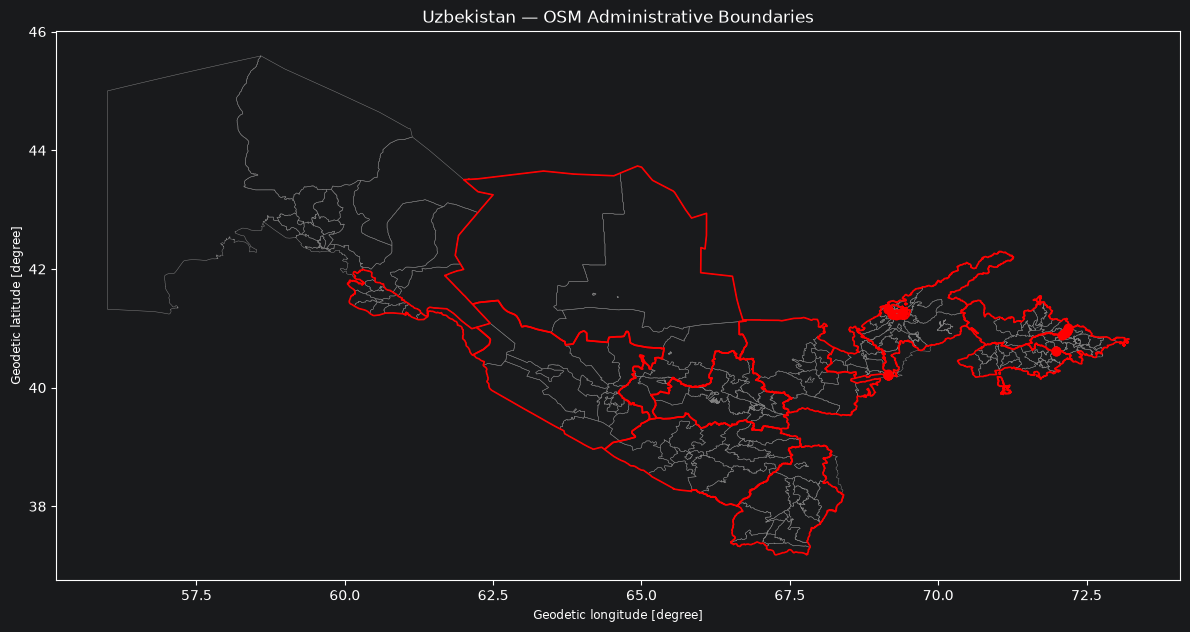

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 9))

districts.plot(
    ax=ax,
    facecolor="none",
    edgecolor="gray",
    linewidth=0.35,
)

regions.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.2,
)

ax.set_title("Uzbekistan — OSM Administrative Boundaries")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [7]:
mask = boundaries["name"].astype("string").str.contains(
    "Qoraqal|Karakal|Каракал|Қарақал",
    case=False,
    na=False
)

display(
    boundaries.loc[
        mask,
        ["id", "name", "admin_level", "geometry"]
    ].assign(
        geometry_type=lambda df: df.geometry.geom_type
    ).drop(columns="geometry")
)

,id,name,admin_level,geometry_type


In [8]:
import osmnx as ox

karakalpakstan = ox.geocode_to_gdf(
    "Karakalpakstan, Uzbekistan"
)

display(
    karakalpakstan[
        ["display_name", "osm_id", "osm_type", "geometry"]
    ]
)

print(karakalpakstan.geometry.geom_type)

,display_name,osm_id,osm_type,geometry
0,"Republic of Karakalpakstan, Uzbekistan",196241,relation,"POLYGON ((55.99855 41.32221, 56.04835 41.31983..."


0    Polygon
dtype: str


Text(0.5, 1.0, 'Karakalpakstan — OSM Boundary')

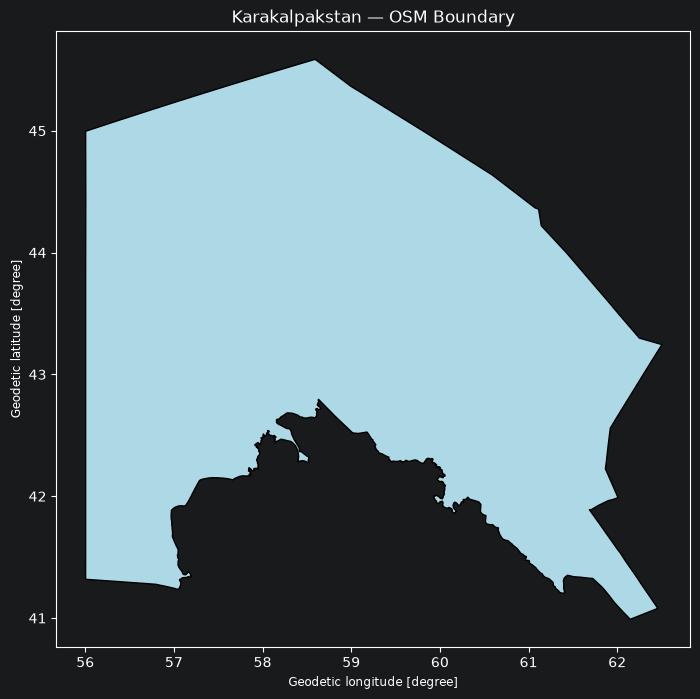

In [9]:
ax = karakalpakstan.plot(
    figsize=(10, 8),
    facecolor="lightblue",
    edgecolor="black"
)

ax.set_title("Karakalpakstan — OSM Boundary")

In [10]:
ox.settings.use_cache = True
ox.settings.log_console = True
ox.settings.requests_timeout = 300

In [11]:

country = ox.geocode_to_gdf("Uzbekistan")

boundaries_online = ox.features_from_polygon(
    country.geometry.iloc[0],
    tags={"boundary": "administrative"}
)

admin = boundaries_online.copy()

admin["admin_level"] = pd.to_numeric(
    admin["admin_level"],
    errors="coerce"
)

regions = admin[
    (admin["admin_level"] == 4)
    & admin.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

districts = admin[
    (admin["admin_level"] == 6)
    & admin.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

print("Regions:", len(regions))
print("Districts:", len(districts))

C:\Users\m.maxsudov\30daymapchallenge-2026\.venv\Lib\site-packages\osmnx\_overpass.py:271: UserWarning: This area is 306 times your configured Overpass max query area size. It will automatically be divided up into multiple sub-queries accordingly. This may take a long time.
  multi_poly_proj = utils_geo._consolidate_subdivide_geometry(poly_proj)


ResponseStatusCodeError: 'overpass-api.de' responded: 502 Bad Gateway # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a short interval, then retry.
If the request fails again, double the wait time and retry again.

## For heavy or automated use

This public endpoint is intended for browser-based and human-operated tools.
For automated or high-volume use, run a local Overpass API instance:

https://github.com/b1tw153/Overpass-API/blob/main/README.md


In [ ]:
display(
    regions[
        ["name", "admin_level"]
    ].sort_values("name")
)

In [ ]:
fig, ax = plt.subplot(figsize=(14, 9))

country.boundary.plot(ax=ax, color='black', linewidth=1.5)
regions.boundary.plot(ax=ax, color='red', linewidth=1)
districts.boundary.plot(ax=ax, color='gray', linewidth=0.3)

ax.set_title("Uzbekistan - OSM Administrative Boundaries")
plt.show()

Пришлось просить ChatGPT восстанавливать недостающиеся полигоны